# DSK821 – **L03 Hands-on: POS Tagging & Dependency Parsing with spaCy**

In this notebook we move from **words to syntactic structure**.

### Learning goals
By the end, you should be able to:
- inspect tokens, lemmas and POS tags;
- identify heads and dependency relations;
- visualize a dependency parse;
- use syntax to answer *who did what to whom?*;
- explore syntactic ambiguity and parser decisions.

We will use the same ideas introduced in the lecture and then finish with short exercises.


## **1. Setup**
Google Colab may already include spaCy, but we install/update the package and download the small English model to make the notebook reproducible.


In [1]:
!pip -q install -U spacy
!python -m spacy download en_core_web_sm -q


✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [2]:
import spacy
from spacy import displacy
from IPython.display import display, HTML

nlp = spacy.load("en_core_web_sm")
print("spaCy version:", spacy.__version__)


spaCy version: 3.8.16


## **2. From a sentence to tokens**
We start with our lecture example.


In [3]:
text = "The curious student reads an interesting book."
doc = nlp(text)

print([token.text for token in doc])


['The', 'curious', 'student', 'reads', 'an', 'interesting', 'book', '.']


## **3. Part-of-Speech tagging**

`token.pos_` gives a coarse-grained POS category. `token.tag_` gives the model's more fine-grained English tag.


In [4]:
import pandas as pd

rows = []
for token in doc:
    rows.append({
        "Token": token.text,
        "Lemma": token.lemma_,
        "POS": token.pos_,
        "Fine tag": token.tag_
    })

pd.DataFrame(rows)


,Token,Lemma,POS,Fine tag
0,The,the,DET,DT
1,curious,curious,ADJ,JJ
2,student,student,NOUN,NN
3,reads,read,VERB,VBZ
4,an,an,DET,DT
5,interesting,interesting,ADJ,JJ
6,book,book,NOUN,NN
7,.,.,PUNCT,.


### Context matters
Compare the POS assigned to **book** in two contexts.


In [7]:
examples = ["I read a book.", "I book a flight.", "book"]
word = "book"

for sentence in examples:
    d = nlp(sentence)
    print("\n", sentence)
    for token in d:
        if token.text.lower() == word:
            print(f"{word} -> POS={token.pos_}, lemma={token.lemma_}, tag={token.tag_}")



 I read a book.
book -> POS=NOUN, lemma=book, tag=NN

 I book a flight.
book -> POS=VERB, lemma=book, tag=VBP

 book
book -> POS=PROPN, lemma=book, tag=NNP


### **Exercise 1**
Try two sentences in which the same word has different grammatical roles. Examples you can test: **refuse**, **record**, or **present**.

**Question:** Does spaCy assign different POS tags and lemmas?


In [6]:
sentence_1 = "They refuse the offer."
sentence_2 = "The refuse was collected."

# TODO: Process both sentences and inspect the target word.


## **4. Dependency parsing**
A dependency parse represents **direct grammatical relationships between words**.

For each token we can inspect:
- `dep_`: its dependency relation;
- `head`: the word it depends on.


In [ ]:
rows = []
for token in doc:
    rows.append({
        "Token": token.text,
        "POS": token.pos_,
        "Dependency": token.dep_,
        "Head": token.head.text
    })

pd.DataFrame(rows)


,Token,POS,Dependency,Head
0,The,DET,det,student
1,curious,ADJ,amod,student
2,student,NOUN,nsubj,reads
3,reads,VERB,ROOT,reads
4,an,DET,det,book
5,interesting,ADJ,amod,book
6,book,NOUN,dobj,reads
7,.,PUNCT,punct,reads


Notice the central relationships in the sentence. For example, the parser identifies a subject connected to **reads** and an object connected to **reads**.


## **5. Visualizing the dependency tree**
spaCy's `displacy` can render the parse directly in the notebook.


In [ ]:
displacy.render(doc, style="dep", jupyter=True, options={"distance": 100})


## **6. Who did what to whom?**
Dependency information can help us extract simple grammatical roles from a sentence.


In [ ]:
sentence = "Apple acquired Beats for three billion dollars."
d = nlp(sentence)

displacy.render(d, style="dep", jupyter=True, options={"distance": 100})

for token in d:
    print(f"{token.text:12} POS={token.pos_:6} DEP={token.dep_:10} HEAD={token.head.text}")


Apple        POS=PROPN  DEP=nsubj      HEAD=acquired
acquired     POS=VERB   DEP=ROOT       HEAD=acquired
Beats        POS=PROPN  DEP=dobj       HEAD=acquired
for          POS=ADP    DEP=prep       HEAD=acquired
three        POS=NUM    DEP=compound   HEAD=billion
billion      POS=NUM    DEP=nummod     HEAD=dollars
dollars      POS=NOUN   DEP=pobj       HEAD=for
.            POS=PUNCT  DEP=punct      HEAD=acquired


In [ ]:
subject = [t.text for t in d if t.dep_ in {"nsubj", "nsubjpass"}]
objects = [t.text for t in d if t.dep_ in {"dobj", "obj"}]
root = [t.text for t in d if t.dep_ == "ROOT"]

print("Subject:", subject)
print("Main predicate/root:", root)
print("Object:", objects)


Subject: ['Apple']
Main predicate/root: ['acquired']
Object: ['Beats']


### **Exercise 2: Analyze a new sentence**
Analyze:

> **The young researcher presented her results at the conference.**

1. Find the POS of each token.
2. Find the root.
3. Find the subject.
4. Find the object.
5. Which word is the head of **conference**?
6. Visualize the dependency tree.


In [ ]:
sentence = "The young researcher presented her results at the conference."
# TODO: process and analyze the sentence

doc2 = nlp(sentence)


import pandas as pd

df = pd.DataFrame()

for i in doc2:
    df[]
    print(i.text, )


The
young
researcher
presented
her
results
at
the
conference
.


## **7. Syntactic ambiguity**
Now consider the sentence from the lecture:

> **I saw the man with the telescope.**

It has at least two possible interpretations:
1. I used a telescope to see the man.
2. The man had the telescope.

A statistical parser normally returns **one analysis**.


In [ ]:
ambiguous = nlp("I saw the man with the telescope.")

displacy.render(ambiguous, style="dep", jupyter=True, options={"distance": 100})

for token in ambiguous:
    print(f"{token.text:12} DEP={token.dep_:10} HEAD={token.head.text}")


I            DEP=nsubj      HEAD=saw
saw          DEP=ROOT       HEAD=saw
the          DEP=det        HEAD=man
man          DEP=dobj       HEAD=saw
with         DEP=prep       HEAD=man
the          DEP=det        HEAD=telescope
telescope    DEP=pobj       HEAD=with
.            DEP=punct      HEAD=saw


### Inspect the attachment
Look specifically at **with** and **telescope**. Which part of the sentence does the parser attach the prepositional phrase to?

**Discussion:** Which interpretation did the model choose? Is that the only valid interpretation?


In [ ]:
for token in ambiguous:
    if token.text.lower() in {"with", "telescope", "man", "saw"}:
        print(token.text, "->", token.dep_, "-> head:", token.head.text)


saw -> ROOT -> head: saw
man -> dobj -> head: saw
with -> prep -> head: man
telescope -> pobj -> head: with


## 8. Mini Challenge – Explore your own sentence
Choose a sentence with at least **8 words**.

Your task:
1. Print token, lemma, POS, dependency and head.
2. Visualize its dependency tree.
3. Identify the root, subject and object (if present).
4. Find at least one modifier.
5. Explain one syntactic relationship in plain English.


In [ ]:
my_sentence = ""

# TODO: analyze your sentence here


# **9. Exercise — Syntactic Ambiguity**

A parser normally returns **one analysis**, even when a sentence has more than one plausible interpretation.

For each sentence:

1. Identify at least **two possible interpretations**.
2. Run the sentence through spaCy.
3. Visualize the dependency parse.
4. Inspect the **head** of the ambiguous phrase.
5. Decide which interpretation spaCy selected.

Remember: the parser's choice is a **model prediction**, not the only possible interpretation.


In [ ]:
ambiguous_sentences = [
    "I saw the man with the telescope.",
    "She watched the girl with the binoculars.",
    "The police arrested the thief in the park.",
    "I photographed the bird on the balcony.",
    "The professor discussed the project with the student."
]

for i, sentence in enumerate(ambiguous_sentences):
    print(f"{i}: {sentence}")


### Analyze one sentence at a time

Change `sentence_id` and rerun the cell. Pay particular attention to words such as **with**, **in**, and **on**: what does the parser attach the prepositional phrase to?


In [ ]:
sentence_id = 0

sentence = ambiguous_sentences[sentence_id]
d = nlp(sentence)

print("Sentence:", sentence)
print()
print(f"{'TOKEN':<15}{'POS':<10}{'DEP':<15}{'HEAD':<15}")
print("-" * 55)

for token in d:
    print(f"{token.text:<15}{token.pos_:<10}{token.dep_:<15}{token.head.text:<15}")

displacy.render(d, style="dep", jupyter=True, options={"distance": 110})


# **10. Named Entity Recognition (NER)**

Named Entity Recognition identifies and classifies entities such as **people, organizations, locations, dates, and monetary values**.

Let's combine NER with dependency parsing.


In [ ]:
text = "Microsoft acquired LinkedIn for $26.2 billion in 2016."
doc = nlp(text)

for ent in doc.ents:
    print(ent.text, "->", ent.label_)


Microsoft -> ORG
LinkedIn -> ORG
$26.2 billion -> MONEY
2016 -> DATE


In [ ]:
displacy.render(doc, style="ent", jupyter=True)


In [ ]:
displacy.render(doc, style="dep", jupyter=True, options={"distance": 100})


# **11. From Text to Relations**

Now we combine the two ideas:

- **NER** tells us which words belong to an entity.
- **Dependency parsing** helps us identify the subject, action, and object.

We will use a synthetic paragraph and extract simple **subject → relation → object** triples.


In [ ]:
text = '''
NovaTech is a technology company based in Copenhagen. Lina Berg founded NovaTech in 2018. NovaTech acquired DataSense in 2024. DataSense develops analytics software. Omar Hassan leads DataSense. NovaTech collaborates with GreenAI. GreenAI is based in Berlin.
'''

doc = nlp(text)

for sent in doc.sents:
    print(sent.text.strip())


NovaTech is a technology company based in Copenhagen.
Lina Berg founded NovaTech in 2018.
NovaTech acquired DataSense in 2024.
DataSense develops analytics software.
Omar Hassan leads DataSense.
NovaTech collaborates with GreenAI. GreenAI is based in Berlin.


### Inspect the analysis

Before extracting relations, inspect how spaCy analyzes the sentences and which named entities it recognizes.


In [ ]:
for sent in doc.sents:
    print("\nSENTENCE:", sent.text.strip())
    for token in sent:
        print(
            f"{token.text:<15} POS={token.pos_:<7} "
            f"DEP={token.dep_:<12} HEAD={token.head.text}"
        )

print("\nNAMED ENTITIES")
for ent in doc.ents:
    print(f"{ent.text:<20} -> {ent.label_}")



SENTENCE: NovaTech is a technology company based in Copenhagen.

               POS=SPACE   DEP=dep          HEAD=NovaTech
NovaTech        POS=PROPN   DEP=nsubj        HEAD=is
is              POS=AUX     DEP=ROOT         HEAD=is
a               POS=DET     DEP=det          HEAD=company
technology      POS=NOUN    DEP=compound     HEAD=company
company         POS=NOUN    DEP=attr         HEAD=is
based           POS=VERB    DEP=acl          HEAD=company
in              POS=ADP     DEP=prep         HEAD=based
Copenhagen      POS=PROPN   DEP=pobj         HEAD=in
.               POS=PUNCT   DEP=punct        HEAD=is

SENTENCE: Lina Berg founded NovaTech in 2018.
Lina            POS=PROPN   DEP=compound     HEAD=Berg
Berg            POS=PROPN   DEP=nsubj        HEAD=founded
founded         POS=VERB    DEP=ROOT         HEAD=founded
NovaTech        POS=PROPN   DEP=dobj         HEAD=founded
in              POS=ADP     DEP=prep         HEAD=founded
2018            POS=NUM     DEP=pobj         HE

### Extract simple relations

For this demonstration, we only extract sentences with a straightforward **subject–verb–object** structure.

If the syntactic head of a subject or object belongs to a named entity, we use the **complete entity name**. For example, `Berg` becomes `Lina Berg`.

This is intentionally a simple teaching example, not a complete relation-extraction system.


In [ ]:
def get_entity(token, doc):
    # Return the complete named entity containing the token, if one exists.
    for ent in doc.ents:
        if ent.start <= token.i < ent.end:
            return ent.text
    return token.text


relations = []

for sent in doc.sents:
    verb = sent.root

    subject = [t for t in verb.children if t.dep_ == "nsubj"]
    obj = [t for t in verb.children if t.dep_ in {"dobj", "obj"}]

    if subject and obj:
        subject_text = get_entity(subject[0], doc)
        object_text = get_entity(obj[0], doc)

        relations.append((subject_text, verb.text, object_text))

for subject, relation, obj in relations:
    print(subject, "--", relation, "-->", obj)


Lina Berg -- founded --> NovaTech
NovaTech -- acquired --> DataSense
DataSense -- develops --> software
Omar Hassan -- leads --> DataSense


# **12. Build a Knowledge Graph**

We can now represent the extracted information as a graph:

- **entities/concepts → nodes**
- **relations → directed edges**


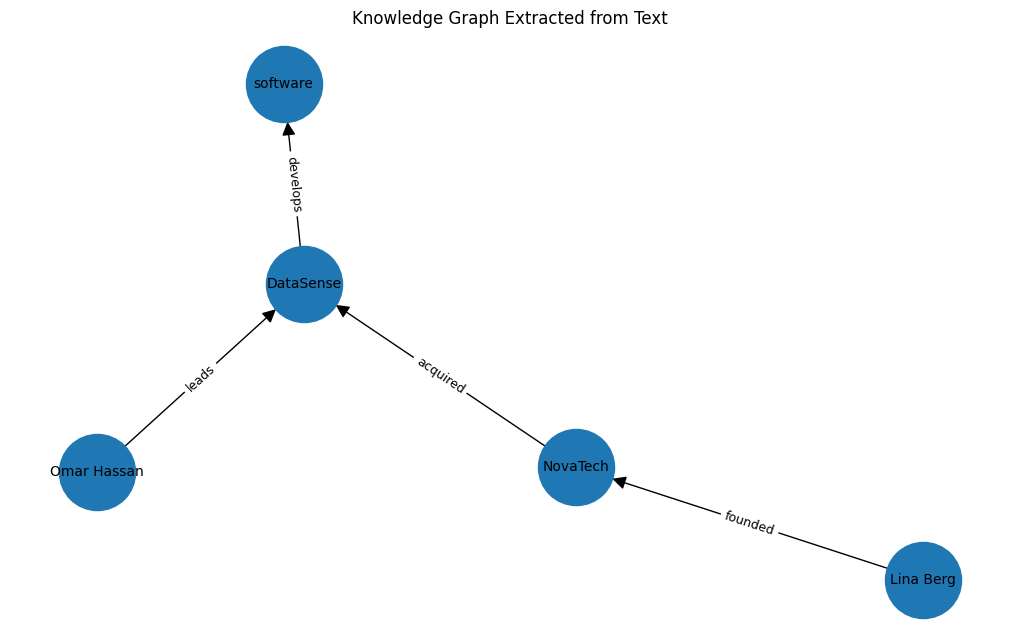

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for subject, relation, obj in relations:
    G.add_edge(subject, obj, relation=relation)

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 6))

nx.draw(
    G, pos,
    with_labels=True,
    node_size=3000,
    font_size=10,
    arrows=True,
    arrowsize=20
)

edge_labels = nx.get_edge_attributes(G, "relation")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9)

plt.title("Knowledge Graph Extracted from Text")
plt.axis("off")
plt.show()


### What did our simple extractor miss?

Look again at:

> **NovaTech collaborates with GreenAI.**  
> **GreenAI is based in Berlin.**

Our extractor focuses on direct **subject–verb–object** structures, so it does not capture every type of relation.

This illustrates an important point: **different syntactic structures require different extraction strategies.**




---


# 🏠 **Take-Home Task: Beyond Simple Subject–Verb–Object Relations**

Our simple relation extractor currently works with sentences that follow a direct:

**Subject → Verb → Object**

For example:

> **Lina Berg founded NovaTech.**

`Lina Berg → founded → NovaTech`

However, our paragraph contains relations that the current extractor does not detect:

> **NovaTech collaborates with GreenAI.**  
> **GreenAI is based in Berlin.**

## Your Task

### **Part 1: Investigate the missing relations**

Use **displaCy** to visualize the dependency structures of these sentences.

Try to understand why our current extractor cannot find:

`NovaTech → collaborates → GreenAI`

and

`GreenAI → based → Berlin`

Consider:

- What is the **ROOT**?
- Where is the **subject**?
- How is the second entity connected to the verb?
- Are there intermediate words between the verb and the entity?
- Which dependency labels appear along the path?

Then modify the extractor so that it can recognize these structures.

---

### **Part 2: What other structures might exist?**

So far, we have only considered a few simple grammatical patterns.

Can the **same relation** be expressed using a different syntactic structure?

For example, compare:

> **NovaTech acquired DataSense.**

with:

> **DataSense was acquired by NovaTech.**

Do they express the same underlying relation?

How does their dependency structure differ?

Think of other ways in which relationships between entities could appear in natural language.

Try writing **2–3 sentences** that express relations but would **not** be correctly handled by our current extractor.

Visualize them with displaCy and investigate their dependency structures.

---

## 💡 Hints

You may want to investigate dependency labels such as:

- `prep`
- `pobj`
- `nsubjpass`
- `agent`

You do **not** need to build a general-purpose relation extraction system.

The goal is to discover an important NLP problem:

> **The same semantic relationship can be expressed through different syntactic structures.**

Think about what this means for automatically extracting knowledge from large collections of text.



---

# **12. Takeaways**

- **POS tagging** assigns grammatical categories to words in context.
- **Dependency parsing** represents relationships between words through head–dependent links.
- **NER** identifies important entities such as people, organizations, locations, dates, and monetary values.
- NER and dependency parsing can be combined to extract **structured relations from text**.
- Extracted relations can be represented as a simple **knowledge graph**.
- Sentences can be **syntactically ambiguous**, while a parser typically returns one analysis.

### Important
spaCy outputs are **model predictions**. Always inspect the analysis when the distinction matters.
